<a href="https://colab.research.google.com/github/nicole205dev/PS-Agents/blob/main/UCS_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import heapq, itertools

ROADS = [
    ("Nairobi",   "Limuru",      37.5),
    ("Nairobi",   "Thika",       45.1),
    ("Nairobi",   "Mai Mahiu",   52.6),
    ("Thika",     "Murang'a",    46.6),
    ("Murang'a",  "Nyeri",       62.2),
    ("Nyeri",     "Nyahururu",   104),
    ("Nyahururu", "Nakuru",      63.3),
    ("Limuru",    "Naivasha",    56.3),
    ("Mai Mahiu", "Naivasha",    34.8),
    ("Mai Mahiu", "Narok",       89.1),
    ("Naivasha",  "Gilgil",      30.4),
    ("Gilgil",    "Nakuru",      41.3),
    ("Nakuru",    "Mau Summit",  24.5),
    ("Mau Summit","Kericho",     82.5),
    ("Mau Summit","Eldoret",     108),
    ("Kericho",   "Sondu",       45),
    ("Sondu",     "Kisumu",      52.6),
    ("Narok",     "Bomet",      81),
    ("Bomet",     "Kericho",     76.1),
    ("Bomet",     "Kisii",       82.4),
    ("Kisii",     "Kisumu",     107),
    ("Eldoret",   "Kakamega",    83.9),
    ("Kakamega",  "Kisumu",      50.9),
]

graph = {}
for a, b, km in ROADS:
    graph.setdefault(a, {})[b] = km    # a -> b
    graph.setdefault(b, {})[a] = km    # b -> a
print(len(graph), "towns loaded")

19 towns loaded


In [2]:
def uniform_cost_search(graph, start, goal):
    counter = itertools.count()          # tie-breaker so equal costs never compare town names
    nodes = []                           # every node ever generated (this is the search tree)

    def make_node(state, parent_id, g):
        nodes.append({"id": len(nodes), "state": state, "parent": parent_id,
                      "g": g, "order": None, "status": "frontier"})
        return len(nodes) - 1

    root = make_node(start, None, 0)
    frontier = [(0, next(counter), root)]    # priority queue ordered by path cost g
    on_frontier = {start: root}              # town -> id of its best frontier node
    explored = set()
    trace = []
    order = 0

    def frontier_snapshot():
        live = [(nodes[i]["g"], nodes[i]["state"]) for _, _, i in frontier
                if nodes[i]["status"] == "frontier"]
        return sorted(live)

    while frontier:
        g, _, nid = heapq.heappop(frontier)
        node = nodes[nid]
        if node["status"] == "superseded":   # an outdated, costlier entry: ignore it
            continue

        state = node["state"]
        on_frontier.pop(state, None)
        order += 1
        node["order"], node["status"] = order, "expanded"

        # Goal test when the node is expanded
        if state == goal:
            path, n = [], node
            while n is not None:
                path.append(n["state"]); n = nodes[n["parent"]] if n["parent"] is not None else None
            trace.append({"step": order, "expand": state, "g": g, "notes": ["GOAL REACHED"],
                          "frontier": frontier_snapshot()})
            return {"path": path[::-1], "cost": g, "trace": trace, "nodes": nodes,
                    "explored": explored | {state}}

        explored.add(state)
        notes = []
        for nbr, km in sorted(graph[state].items()):
            new_g = g + km
            if nbr in explored:
                notes.append(f"{nbr}: already explored, skip")
            elif nbr in on_frontier:
                old = nodes[on_frontier[nbr]]
                if new_g < old["g"]:
                    old["status"] = "superseded"
                    new_id = make_node(nbr, nid, new_g)
                    on_frontier[nbr] = new_id
                    heapq.heappush(frontier, (new_g, next(counter), new_id))
                    notes.append(f"{nbr}: cheaper path found, g = {new_g} (was {old['g']}), replace")
                else:
                    notes.append(f"{nbr}: g = {new_g} is not cheaper than {old['g']}, keep old")
            else:
                new_id = make_node(nbr, nid, new_g)
                on_frontier[nbr] = new_id
                heapq.heappush(frontier, (new_g, next(counter), new_id))
                notes.append(f"{nbr}: add to frontier, g = {new_g}")

        trace.append({"step": order, "expand": state, "g": g, "notes": notes,
                      "frontier": frontier_snapshot()})
    return None

START, GOAL = "Nairobi", "Kisumu"
result = uniform_cost_search(graph, START, GOAL)
print("Search finished.")

Search finished.


###  Step-by-step trace
Each step shows the node removed from the frontier (the one with the lowest g), what happens to its neighbours, and the frontier afterwards (sorted, cheapest first).

In [3]:
for t in result["trace"]:
    print(f"Step {t['step']:>2}: expand {t['expand']}  (g = {t['g']} km)")
    for note in t["notes"]:
        print(f"         - {note}")
    fr = ", ".join(f"{town}({g})" for g, town in t["frontier"])
    print(f"         Frontier: [{fr}]")
    print()

Step  1: expand Nairobi  (g = 0 km)
         - Limuru: add to frontier, g = 37.5
         - Mai Mahiu: add to frontier, g = 52.6
         - Thika: add to frontier, g = 45.1
         Frontier: [Limuru(37.5), Thika(45.1), Mai Mahiu(52.6)]

Step  2: expand Limuru  (g = 37.5 km)
         - Nairobi: already explored, skip
         - Naivasha: add to frontier, g = 93.8
         Frontier: [Thika(45.1), Mai Mahiu(52.6), Naivasha(93.8)]

Step  3: expand Thika  (g = 45.1 km)
         - Murang'a: add to frontier, g = 91.7
         - Nairobi: already explored, skip
         Frontier: [Mai Mahiu(52.6), Murang'a(91.7), Naivasha(93.8)]

Step  4: expand Mai Mahiu  (g = 52.6 km)
         - Nairobi: already explored, skip
         - Naivasha: cheaper path found, g = 87.4 (was 93.8), replace
         - Narok: add to frontier, g = 141.7
         Frontier: [Naivasha(87.4), Murang'a(91.7), Narok(141.7)]

Step  5: expand Naivasha  (g = 87.4 km)
         - Gilgil: add to frontier, g = 117.80000000000001
     

In [5]:
import pandas as pd

# Summary: the order in which towns were expanded
order_table = pd.DataFrame([
    {"Expansion order": t["step"],
     "Town expanded": t["expand"],
     "Path cost g(n) (km)": t["g"]}
    for t in result["trace"]
])
order_table

,Expansion order,Town expanded,Path cost g(n) (km)
0,1,Nairobi,0.0
1,2,Limuru,37.5
2,3,Thika,45.1
3,4,Mai Mahiu,52.6
4,5,Naivasha,87.4
5,6,Murang'a,91.7
6,7,Gilgil,117.8
7,8,Narok,141.7
8,9,Nyeri,153.9
9,10,Nakuru,159.1


##  Search tree
Every node generated by UCS is shown with its path cost g. The number in brackets is the **order of expansion**. Nodes with no number were generated but never expanded, because the goal was reached first. Nodes marked *replaced* were later reached by a cheaper route.

In [6]:
nodes = result["nodes"]
children = {n["id"]: [] for n in nodes}
for n in nodes:
    if n["parent"] is not None:
        children[n["parent"]].append(n["id"])
for k in children:
    children[k].sort(key=lambda i: nodes[i]["g"])

def label(n):
    if n["order"] is not None:
        tag = f"[expanded #{n['order']}]"
    elif n["status"] == "superseded":
        tag = "[replaced by a cheaper path]"
    else:
        tag = "[generated, not expanded]"
    return f"{n['state']} (g = {n['g']}) {tag}"

def print_tree(nid=0, prefix="", last=True):
    n = nodes[nid]
    connector = "" if nid == 0 else ("└── " if last else "├── ")
    print(prefix + connector + label(n))
    new_prefix = prefix + ("" if nid == 0 else ("    " if last else "│   "))
    kids = children[nid]
    for i, c in enumerate(kids):
        print_tree(c, new_prefix, i == len(kids) - 1)

print_tree()

Nairobi (g = 0) [expanded #1]
├── Limuru (g = 37.5) [expanded #2]
│   └── Naivasha (g = 93.8) [replaced by a cheaper path]
├── Thika (g = 45.1) [expanded #3]
│   └── Murang'a (g = 91.7) [expanded #6]
│       └── Nyeri (g = 153.9) [expanded #9]
│           └── Nyahururu (g = 257.9) [replaced by a cheaper path]
└── Mai Mahiu (g = 52.6) [expanded #4]
    ├── Naivasha (g = 87.4) [expanded #5]
    │   └── Gilgil (g = 117.80000000000001) [expanded #7]
    │       └── Nakuru (g = 159.10000000000002) [expanded #10]
    │           ├── Mau Summit (g = 183.60000000000002) [expanded #11]
    │           │   ├── Kericho (g = 266.1) [expanded #14]
    │           │   │   └── Sondu (g = 311.1) [expanded #17]
    │           │   │       └── Kisumu (g = 363.70000000000005) [expanded #18]
    │           │   └── Eldoret (g = 291.6) [expanded #15]
    │           │       └── Kakamega (g = 375.5) [generated, not expanded]
    │           └── Nyahururu (g = 222.40000000000003) [expanded #12]
    └── Narok

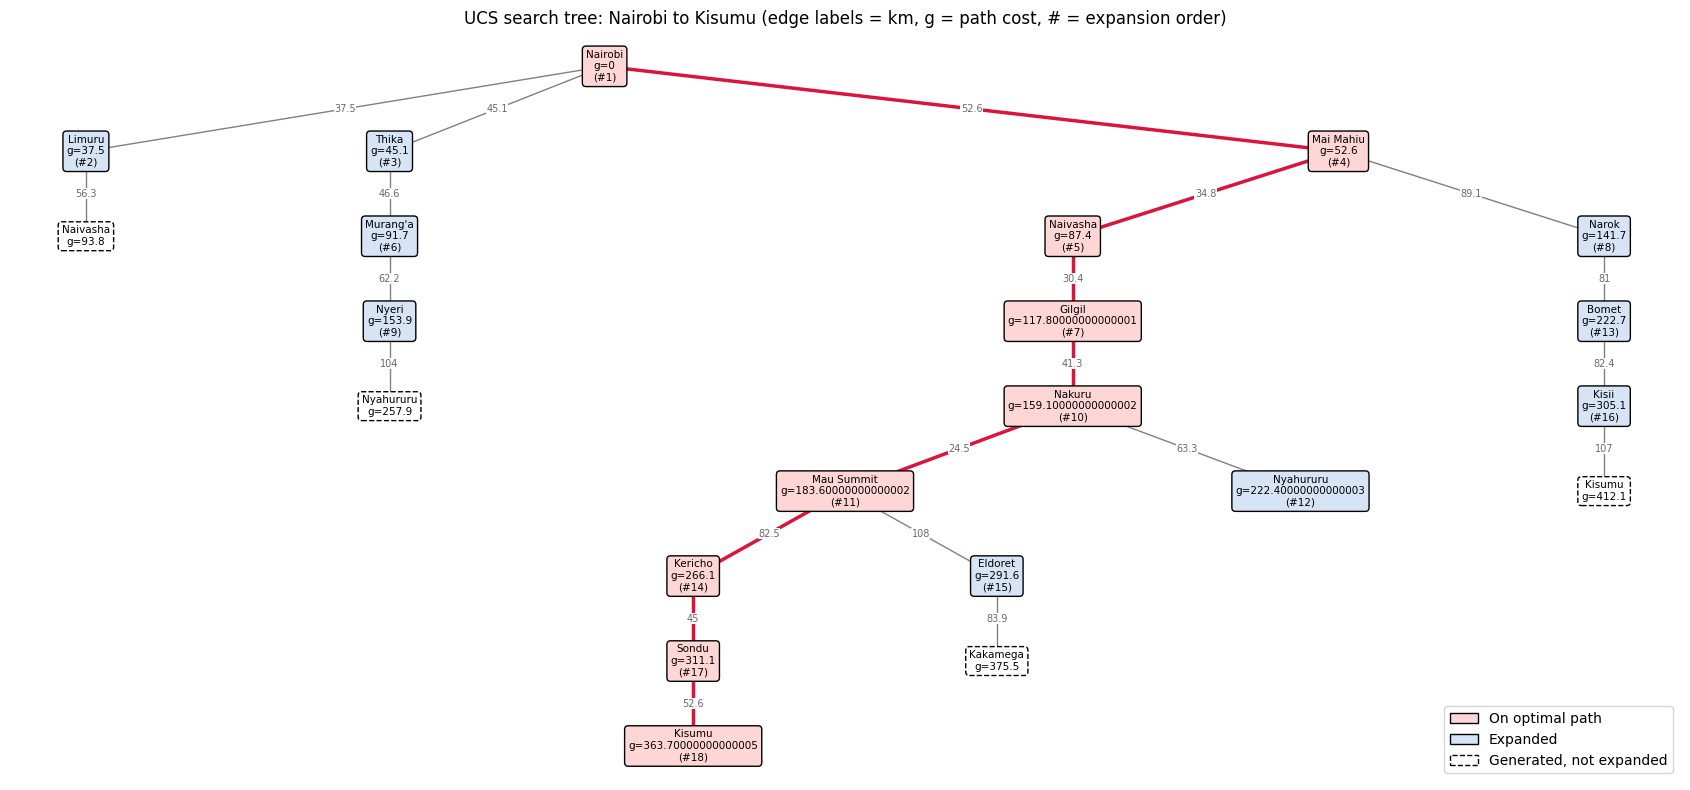

In [9]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

optimal_ids = set()
goal_node = [n for n in nodes if n["state"] == GOAL and n["order"] is not None][0]
nid = goal_node["id"]
while nid is not None:
    optimal_ids.add(nid)
    nid = nodes[nid]["parent"]

pos, counter_x = {}, [0]

def layout(nid, depth=0):
    kids = children[nid]
    if not kids:
        pos[nid] = (counter_x[0], -depth)
        counter_x[0] += 1
    else:
        for c in kids:
            layout(c, depth + 1)
        pos[nid] = (sum(pos[c][0] for c in kids) / len(kids), -depth)

layout(0)

fig, ax = plt.subplots(figsize=(17, 8))

for n in nodes:
    if n["parent"] is not None:
        (x1, y1), (x2, y2) = pos[n["parent"]], pos[n["id"]]
        on_opt = n["id"] in optimal_ids
        ax.plot([x1, x2], [y1, y2],
                color="crimson" if on_opt else "grey",
                linewidth=2.5 if on_opt else 1, zorder=1)
        km = graph[nodes[n["parent"]]["state"]][n["state"]]
        ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(km), fontsize=7, color="dimgrey",
                ha="center", va="center",
                bbox=dict(fc="white", ec="none", pad=0.3))

for n in nodes:
    x, y = pos[n["id"]]
    if n["id"] in optimal_ids:
        fc = "#ffd6d6"
    elif n["order"] is not None:
        fc = "#d6e4f5"
    else:
        fc = "white"
    ls = "--" if n["order"] is None else "-"
    order_txt = f"\n(#{n['order']})" if n["order"] is not None else ""
    ax.text(x, y, f"{n['state']}\ng={n['g']}{order_txt}",
            ha="center", va="center", fontsize=7.5,
            bbox=dict(boxstyle="round,pad=0.35", fc=fc, ec="black", ls=ls),
            zorder=3)

ax.legend(handles=[
    Patch(fc="#ffd6d6", ec="black", label="On optimal path"),
     Patch(fc="#d6e4f5", ec="black", label="Expanded"),
    Patch(fc="white", ec="black", ls="--", label="Generated, not expanded"),
], loc="lower right")

ax.set_title("UCS search tree: Nairobi to Kisumu (edge labels = km, g = path cost, # = expansion order)")
ax.axis("off")
plt.tight_layout()
plt.show()

##  Optimal path and cost

In [10]:
path, total = result["path"], result["cost"]

legs, running = [], 0
for a, b in zip(path, path[1:]):
    km = graph[a][b]; running += km
    legs.append({"From": a, "To": b, "Leg distance (km)": km, "Cumulative (km)": running})
display_legs = pd.DataFrame(legs)
print("OPTIMAL PATH :", " -> ".join(path))
print("TOTAL COST   :", total, "km")
print("Towns expanded:", len(result["trace"]), "| Nodes generated:", len(result["nodes"]))
display_legs

OPTIMAL PATH : Nairobi -> Mai Mahiu -> Naivasha -> Gilgil -> Nakuru -> Mau Summit -> Kericho -> Sondu -> Kisumu
TOTAL COST   : 363.70000000000005 km
Towns expanded: 18 | Nodes generated: 22


,From,To,Leg distance (km),Cumulative (km)
0,Nairobi,Mai Mahiu,52.6,52.6
1,Mai Mahiu,Naivasha,34.8,87.4
2,Naivasha,Gilgil,30.4,117.8
3,Gilgil,Nakuru,41.3,159.1
4,Nakuru,Mau Summit,24.5,183.6
5,Mau Summit,Kericho,82.5,266.1
6,Kericho,Sondu,45.0,311.1
7,Sondu,Kisumu,52.6,363.7


In [ ]:
draw_graph(path, title=f"Optimal path from {START} to {GOAL}: {total} km")

## Verification: compare with every possible route
To check the answer, we list **all** simple (non-repeating) routes from Nairobi to Kisumu and compare their costs. UCS should return the cheapest one.

In [11]:
def all_routes(graph, start, goal):
    routes = []
    def dfs(town, visited, cost):
        if town == goal:
            routes.append((cost, list(visited))); return
        for nbr, km in graph[town].items():
            if nbr not in visited:
                visited.append(nbr); dfs(nbr, visited, cost + km); visited.pop()
    dfs(start, [start], 0)
    return sorted(routes)

routes = all_routes(graph, START, GOAL)
comparison = pd.DataFrame([{"Rank": i + 1, "Total cost (km)": c, "Route": " -> ".join(r)}
                           for i, (c, r) in enumerate(routes)])
print("Number of possible routes:", len(routes))
assert routes[0][0] == total, "UCS result does not match the cheapest route!"
print("Check passed: UCS cost matches the cheapest of all routes.")
comparison.head(8)

Number of possible routes: 18
Check passed: UCS cost matches the cheapest of all routes.


,Rank,Total cost (km),Route
0,1,363.7,Nairobi -> Mai Mahiu -> Naivasha -> Gilgil -> ...
1,2,370.1,Nairobi -> Limuru -> Naivasha -> Gilgil -> Nak...
2,3,396.4,Nairobi -> Mai Mahiu -> Narok -> Bomet -> Keri...
3,4,412.1,Nairobi -> Mai Mahiu -> Narok -> Bomet -> Kisi...
4,5,426.4,Nairobi -> Mai Mahiu -> Naivasha -> Gilgil -> ...
5,6,432.8,Nairobi -> Limuru -> Naivasha -> Gilgil -> Nak...
6,7,472.4,Nairobi -> Limuru -> Naivasha -> Mai Mahiu -> ...
7,8,488.1,Nairobi -> Limuru -> Naivasha -> Mai Mahiu -> ...
